# Notebook 04 — LIME Local Explanations (J26-IT-388, Component 4)

**Research task:** Explain the **frozen** Dreaddit TF-IDF + Logistic Regression classifier from Notebook 02. Compare local token explanations with Notebook 03 SHAP results without retraining or test-set tuning.

**Outputs:** LIME example figures, fidelity measurements, repeated-seed stability, runtime benchmarks, qualitative SHAP term overlap, reproducibility manifest, PP1 evidence. This is stress-related _text classification_, **not clinical mental-health risk diagnosis**.

**Methodology cautions:** LIME perturbs the input text and fits a _local surrogate_ in **class-1 probability space**. Its weights are **not** SHAP log-odds contributions and must not be numerically equated. High surrogate fidelity describes a local approximation—not clinical validity, faithfulness on unseen realistic texts, or causality.


## 0. Dependencies and kernel

Run once in your activated VS Code `.venv` terminal:

```cmd
python -m pip install "lime>=0.2.0.1,<0.3" pandas numpy scipy scikit-learn matplotlib joblib ipykernel jupyter
```

Use your project's `.venv` kernel. **Do not retrain the model.** For stable reproduction, preserve your installed package versions in the exported manifest.


In [1]:
from pathlib import Path
import hashlib, json, platform, sys, time, re
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
from lime.lime_text import LimeTextExplainer
import lime
from IPython.display import display

SEED = 42
N_LIME_FEATURES = 12
N_LIME_PERTURBATIONS = 1000
N_REPEATS = 5
N_STABILITY_CASES = 4
N_RUNTIME_CASES = 8
N_SHAP_COMPARE_TOP = 12

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents] if (p/'models/dreaddit_tfidf_logreg.joblib').exists() and (p/'data/raw/dreaddit/dreaddit-test.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Saved model and Dreaddit CSV must exist in your repository; open notebook from repo or notebooks folder.')
MODEL_PATH = ROOT/'models/dreaddit_tfidf_logreg.joblib'
TRAIN_PATH = ROOT/'data/raw/dreaddit/dreaddit-train.csv'
TEST_PATH = ROOT/'data/raw/dreaddit/dreaddit-test.csv'
M_DIR = ROOT/'experiments/metrics/notebook04'
F_DIR = ROOT/'experiments/figures/notebook04'
M_DIR.mkdir(parents=True,exist_ok=True)
F_DIR.mkdir(parents=True,exist_ok=True)
print('Root:', ROOT)
print('Python:',platform.python_version(),'sklearn:',sklearn.__version__)
print('LIME installed:',getattr(lime,'__version__','version not exposed'))

Root: E:\DevPlux\Campus - Research Projects\J26-IT-388_G41\J26-IT-388
Python: 3.12.0 sklearn: 1.8.0
LIME installed: version not exposed


## 1. Load and freeze prediction model

Only load a trusted model created by your own Notebook 02; `joblib.load()` uses pickle serialization. No `.fit()` occurs in this notebook. LIME fits a **surrogate to perturbed predictions**, but does **not** retrain the original predictor.


In [2]:
pipe = joblib.load(MODEL_PATH)
assert list(pipe.named_steps) == ['tfidf', 'model'], 'Unexpected pipeline format; inspect before proceeding'
assert isinstance(pipe.named_steps['model'], sklearn.linear_model.LogisticRegression)
assert pipe.named_steps['model'].classes_.tolist() == [0,1]
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
assert {'text','label'}.issubset(train.columns) and {'text','label'}.issubset(test.columns)
assert test['text'].notna().all() and set(test['label'].unique())=={0,1}
texts = test['text'].astype(str).tolist()
y_true = test['label'].astype(int).to_numpy()
probs = pipe.predict_proba(texts)[:,1]
y_pred = (probs>=0.5).astype(int)
assert len(texts)==715 and probs.min()>=0 and probs.max()<=1
baseline_probs = probs.copy()
print('Frozen model:', MODEL_PATH.name, '| held-out size:',len(texts))
print('Prediction consistency check:',np.array_equal(pipe.predict(texts),y_pred))

e:\DevPlux\Campus - Research Projects\J26-IT-388_G41\J26-IT-388\.venv\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
e:\DevPlux\Campus - Research Projects\J26-IT-388_G41\J26-IT-388\.venv\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.9.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
e:\DevPlux\Campus - Research Projects\J26-IT-388_G41\J26-IT-388\.venv\Lib\site-packages\sklearn\base.py:463: Incons

Frozen model: dreaddit_tfidf_logreg.joblib | held-out size: 715
Prediction consistency check: True


## 2. Use the _same_ held-out case rows as Notebook 03

Notebook 03's example rows are: TP = 10, TN = 1, FP = 22, FN = 53. Verify their types against the loaded model before explaining. **These fixed cases are for visualization and method comparison, not test-set model selection.**


In [3]:
CASES = {'true_positive':10, 'true_negative':1, 'false_positive':22, 'false_negative':53}
for name, idx in CASES.items():
    truth, prediction = int(y_true[idx]),int(y_pred[idx])
    condition = {'true_positive':(1,1),'true_negative':(0,0),'false_positive':(0,1),'false_negative':(1,0)}[name]
    assert (truth,prediction)==condition, f'{name}: case no longer matches Notebook 03 model; confirm same model file.'
case_table=pd.DataFrame([{'case':name,'test_row':idx,'true_label':int(y_true[idx]),'predicted_label':int(y_pred[idx]),'p_stress':float(probs[idx])} for name,idx in CASES.items()])
display(case_table)
case_table.to_csv(M_DIR/'selected_cases.csv',index=False)

,case,test_row,true_label,predicted_label,p_stress
0,true_positive,10,1,1,0.584680
1,true_negative,1,0,0,0.450695
2,false_positive,22,0,1,0.634791
3,false_negative,53,1,0,0.418586


## 3. LIME local explanations

`LimeTextExplainer` perturbs text by removing words and fits a weighted local linear surrogate. Because input to the explainer is **raw text**, `pipe.predict_proba` includes _exactly the same fitted TF-IDF transformation_ used by the frozen classifier.

Per-case output:

- `as_list(label=1)`: signed **local surrogate** importance toward class-1 probability.
- `score`: LIME's local weighted surrogate R², which may be negative or exceed typical intuitive expectations in edge cases.
- `local_pred`: local surrogate approximation at the original example.
- `predict_proba[1]`: actual frozen model probability.

They do **not** guarantee SHAP agreement.


In [4]:
def explain_one(text, seed, num_samples=N_LIME_PERTURBATIONS):
    exp=LimeTextExplainer(class_names=['Non-stress-related','Stress-related'], random_state=int(seed), bow=True)
    t0=time.perf_counter()
    result=exp.explain_instance(text, pipe.predict_proba, labels=(1,), num_features=N_LIME_FEATURES, num_samples=int(num_samples))
    elapsed=time.perf_counter()-t0
    return result, elapsed

records=[]; explanation_metadata=[]; example_explanations={}
for case,idx in CASES.items():
    exp,seconds=explain_one(texts[idx],SEED+idx)
    example_explanations[case]=exp
    local_approx=np.asarray(exp.local_pred).reshape(-1)
    approx=float(local_approx[0]) if len(local_approx) else float('nan')
    explanation_metadata.append({'case':case,'test_row':int(idx),'true_label':int(y_true[idx]),'pred_label':int(y_pred[idx]),
        'model_probability':float(probs[idx]),'lime_surrogate_probability':approx,
        'abs_surrogate_probability_error':abs(approx-float(probs[idx])),
        'local_weighted_r2':float(exp.score),'elapsed_seconds':seconds,'n_perturbations':N_LIME_PERTURBATIONS})
    for rank,(term,weight) in enumerate(exp.as_list(label=1),start=1):
        records.append({'case':case,'test_row':int(idx),'rank':rank,'term':str(term),'lime_weight_probability_surrogate':float(weight),
                        'model_probability':float(probs[idx]), 'local_weighted_r2':float(exp.score)})

lime_rows=pd.DataFrame(records)
meta_df=pd.DataFrame(explanation_metadata)
lime_rows.to_csv(M_DIR/'lime_local_terms.csv',index=False)
meta_df.to_csv(M_DIR/'lime_local_fidelity.csv',index=False)
display(meta_df.round(5))

,case,test_row,true_label,pred_label,model_probability,lime_surrogate_probability,abs_surrogate_probability_error,local_weighted_r2,elapsed_seconds,n_perturbations
0,true_positive,10,1,1,0.58468,0.58705,0.00237,0.86595,0.10284,1000
1,true_negative,1,0,0,0.45069,0.45753,0.00683,0.83318,0.16714,1000
2,false_positive,22,0,1,0.63479,0.64000,0.00521,0.74927,0.15828,1000
3,false_negative,53,1,0,0.41859,0.40883,0.00975,0.79126,0.15628,1000


## 4. Save local explanation figures

Positive LIME weights push the _surrogate's_ estimate toward the stress-related class; negative weights pull it away. This is **not a percentage-point causal effect**. Review words before sharing figures publicly.


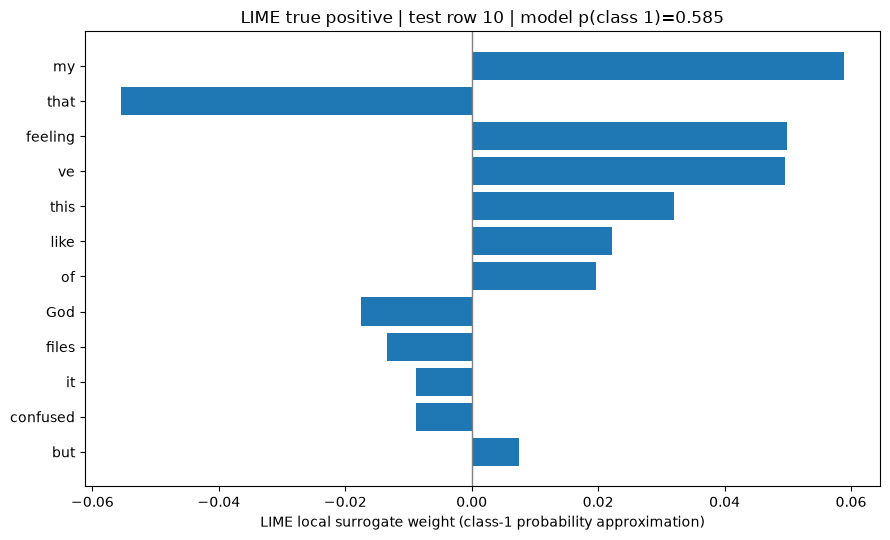

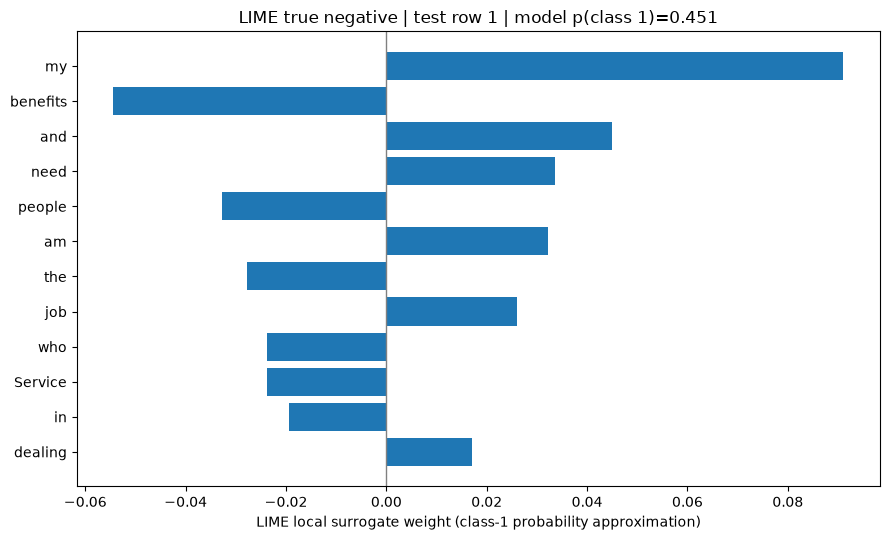

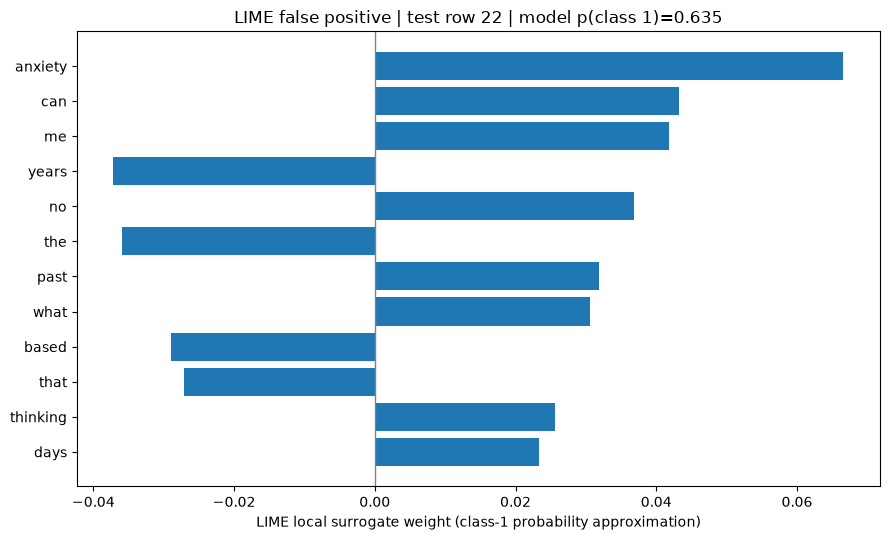

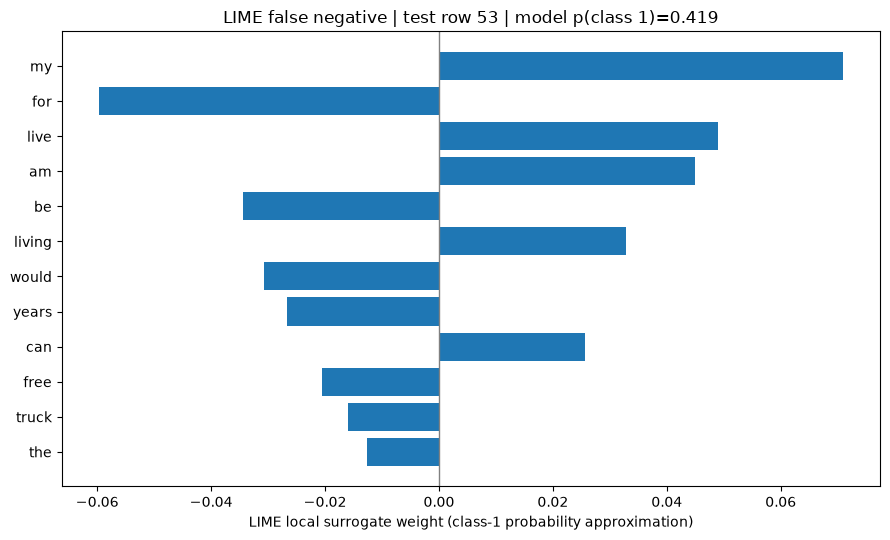

In [5]:
for case, exp in example_explanations.items():
    terms,weights=zip(*exp.as_list(label=1))
    fig, ax = plt.subplots(figsize=(9,5.5))
    pos=np.arange(len(terms))[::-1]
    ax.barh(pos,weights)
    ax.set_yticks(pos,terms)
    ax.axvline(0,color='grey',lw=1)
    ax.set_xlabel('LIME local surrogate weight (class-1 probability approximation)')
    idx=CASES[case]
    ax.set_title(f'LIME {case.replace("_"," ")} | test row {idx} | model p(class 1)={probs[idx]:.3f}')
    fig.tight_layout()
    fig.savefig(F_DIR/f'01_lime_{case}.png',dpi=180,bbox_inches='tight')
    plt.show()

## 5. Surrogate fidelity summary

LIME surrogate fidelity is reported for this perturbation distribution and these fixed cases only. If fidelity is weak, do not treat the local ranking as reliably approximating the classifier near that text. No forced acceptance threshold is assumed.


In [6]:
fidelity_summary={
    'n_cases':int(len(meta_df)),
    'mean_local_weighted_r2':float(meta_df.local_weighted_r2.mean()),
    'min_local_weighted_r2':float(meta_df.local_weighted_r2.min()),
    'mean_abs_surrogate_probability_error':float(meta_df.abs_surrogate_probability_error.mean()),
    'max_abs_surrogate_probability_error':float(meta_df.abs_surrogate_probability_error.max()),
    'note':'R2 on LIME perturbed neighborhood, not out-of-sample predictive R2'}
(M_DIR/'lime_fidelity_summary.json').write_text(json.dumps(fidelity_summary,indent=2),encoding='utf-8')
display(pd.DataFrame([fidelity_summary]))

,n_cases,mean_local_weighted_r2,min_local_weighted_r2,mean_abs_surrogate_probability_error,max_abs_surrogate_probability_error,note
0,4,0.809916,0.749268,0.006042,0.009754,"R2 on LIME perturbed neighborhood, not out-of-..."


## 6. Perturbation randomness / explanation stability

Run repeated LIME explanations with different independent seeds on the _same four frozen inputs_. Compare top-term Jaccard overlap and sign agreement on shared terms. This measures procedural stability under LIME randomness; it is **not** clinical or human-interpretability validation.


In [7]:
def top_features(exp, k=N_LIME_FEATURES):
    return {str(t).casefold().strip():float(w) for t,w in exp.as_list(label=1)[:k]}

def pair_stats(a,b):
    ka,kb=set(a),set(b)
    union=ka|kb; shared=ka&kb
    return {
        'jaccard':float(len(shared)/len(union)) if union else float('nan'),
        'sign_agreement_shared':float(np.mean([np.sign(a[t])==np.sign(b[t]) for t in shared])) if shared else float('nan'),
        'shared_count':len(shared)}

stability=[]
for case,idx in list(CASES.items())[:N_STABILITY_CASES]:
    runs=[]
    for repeat in range(N_REPEATS):
        exp,elapsed=explain_one(texts[idx],SEED+10000+idx*10+repeat)
        runs.append((top_features(exp),elapsed,float(exp.score)))
    for i in range(len(runs)):
        for j in range(i+1,len(runs)):
            z=pair_stats(runs[i][0],runs[j][0])
            stability.append({'case':case,'repeat_a':i,'repeat_b':j,**z})
stability_df=pd.DataFrame(stability)
stability_df.to_csv(M_DIR/'lime_stability_pairs.csv',index=False)
stability_summary={'n_seeds_per_case':N_REPEATS,'n_cases':N_STABILITY_CASES,
 'mean_top_term_jaccard':float(stability_df.jaccard.mean()),
 'min_top_term_jaccard':float(stability_df.jaccard.min()),
 'mean_sign_agreement_shared_terms':float(stability_df.sign_agreement_shared.mean()) if stability_df.sign_agreement_shared.notna().any() else None}
(M_DIR/'lime_stability_summary.json').write_text(json.dumps(stability_summary,indent=2),encoding='utf-8')
display(stability_df.groupby('case')[['jaccard','sign_agreement_shared']].mean().round(3))

,jaccard,sign_agreement_shared
case,,
false_negative,0.892,1.0
false_positive,0.830,1.0
true_negative,0.835,1.0
true_positive,0.877,1.0


## 7. SHAP vs LIME: _qualitative_ local top-term comparison

Read **Notebook 03's saved local SHAP terms**, if available. Because SHAP reports **log-odds attributions** relative to a background whereas LIME reports **local surrogate probability-space coefficients**, compare **top-term overlap and signs only**, not weights or their magnitudes.

A missing Notebook 03 file will be reported clearly; the LIME notebook can still finish standalone.


In [8]:
SHAP_LOCAL = ROOT/'experiments/metrics/notebook03/local_shap_examples.csv'
compare_rows=[]
if SHAP_LOCAL.exists():
    shap_rows=pd.read_csv(SHAP_LOCAL)
    required={'case','term','shap_log_odds','original_test_row'}
    if not required.issubset(shap_rows.columns):
        print('SHAP local CSV has a different schema; comparison skipped.')
    else:
        for case,idx in CASES.items():
            one=shap_rows[(shap_rows['case']==case)&(shap_rows['original_test_row']==idx)]
            if one.empty:
                print('No SHAP terms for',case,'row',idx)
                continue
            shap_top={str(t).casefold().strip():float(v) for t,v in zip(one.term,one.shap_log_odds)}
            lime_top=top_features(example_explanations[case],N_SHAP_COMPARE_TOP)
            scores=pair_stats(shap_top,lime_top)
            compare_rows.append({'case':case,'test_row':idx,**scores,'comparison_note':'SHAP log-odds vs LIME surrogate probability: magnitudes not comparable'})
else:
    print('SHAP local CSV not found. Run Notebook 03 first for optional method comparison:',SHAP_LOCAL)
comparison_df=pd.DataFrame(compare_rows,columns=['case','test_row','jaccard','sign_agreement_shared','shared_count','comparison_note'])
comparison_df.to_csv(M_DIR/'shap_lime_term_comparison.csv',index=False)
if len(comparison_df): display(comparison_df.round(3))

,case,test_row,jaccard,sign_agreement_shared,shared_count,comparison_note
0,true_positive,10,0.263,1.0,5,SHAP log-odds vs LIME surrogate probability: m...
1,true_negative,1,0.500,1.0,8,SHAP log-odds vs LIME surrogate probability: m...
2,false_positive,22,0.333,1.0,6,SHAP log-odds vs LIME surrogate probability: m...
3,false_negative,53,0.412,1.0,7,SHAP log-odds vs LIME surrogate probability: m...


## 8. Local request runtime (separate from model training)

LIME requires many model evaluations for each explanation. Measure _warm_ individual explanation wall-time on a fixed small set of held-out rows, using the same perturbation count. These timings include perturbation generation and repeated model inference, but not API/network/frontend costs. **Do not describe this as production latency.**


,test_row,elapsed_seconds,num_perturbations
0,10,0.101,1000
1,1,0.150,1000
2,22,0.173,1000
3,53,0.154,1000
4,100,0.157,1000
5,200,0.126,1000
6,300,0.218,1000
7,400,0.149,1000


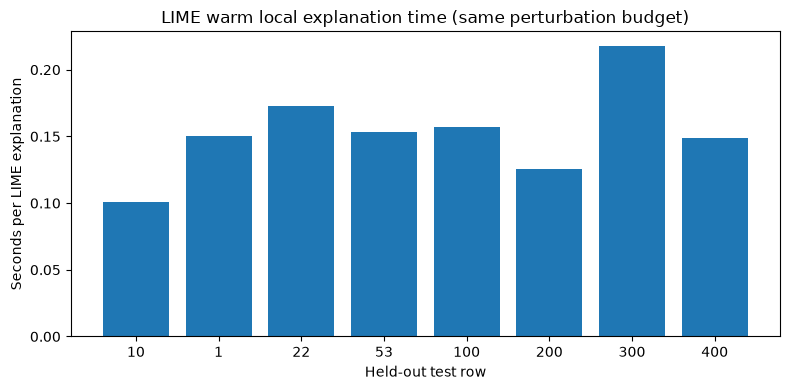

In [9]:
# First four are Notebook 03 cases, followed by predetermined held-out indices.
runtime_idxs=list(CASES.values()) + [100,200,300,400]
runtime_idxs=runtime_idxs[:N_RUNTIME_CASES]
# warm up Python/vectorizer before timed calls
_ = pipe.predict_proba([texts[runtime_idxs[0]]])
measured=[]
for idx in runtime_idxs:
    _,elapsed=explain_one(texts[idx],SEED+20000+idx)
    measured.append({'test_row':int(idx),'elapsed_seconds':float(elapsed),'num_perturbations':int(N_LIME_PERTURBATIONS)})
runtime_df=pd.DataFrame(measured)
runtime_df.to_csv(M_DIR/'lime_runtime_by_case.csv',index=False)
runtime_summary={'requests':len(runtime_df),
  'mean_seconds_per_explanation':float(runtime_df.elapsed_seconds.mean()),
  'median_seconds_per_explanation':float(runtime_df.elapsed_seconds.median()),
  'p95_seconds_per_explanation':float(np.percentile(runtime_df.elapsed_seconds,95)),
  'num_perturbations':N_LIME_PERTURBATIONS,
  'warning':'Local warm execution time; NOT end-to-end API or dashboard latency'}
(M_DIR/'lime_runtime_summary.json').write_text(json.dumps(runtime_summary,indent=2),encoding='utf-8')
display(runtime_df.round(3))
fig,ax=plt.subplots(figsize=(8,4))
ax.bar([str(i) for i in runtime_df.test_row],runtime_df.elapsed_seconds)
ax.set_xlabel('Held-out test row');ax.set_ylabel('Seconds per LIME explanation')
ax.set_title('LIME warm local explanation time (same perturbation budget)')
fig.tight_layout();fig.savefig(F_DIR/'02_lime_runtime.png',dpi=180);plt.show()

## 9. Integrity, reproducibility and final evidence summary

Test that LIME has not modified the saved prediction model by comparing probabilities with those computed before explanation. Record file hashes, hyperparameters and library versions. **No fitting of original model and no changes to the held-out labels**.


In [10]:
after=pipe.predict_proba(texts)[:,1]
max_prediction_change=float(np.max(np.abs(after-baseline_probs)))
assert max_prediction_change < 1e-12,'Frozen model predictions changed unexpectedly!'
def digest(path):
    h=hashlib.sha256()
    with open(path,'rb') as fh:
        for part in iter(lambda:fh.read(1024*1024),b''):h.update(part)
    return h.hexdigest()

summary={
 'project':'J26-IT-388 Component 4','notebook':'04_lime_explanations',
 'generated_utc':datetime.now(timezone.utc).isoformat(),
 'task':'LIME explanations of frozen stress-related-text classifier; no original model training',
 'model_sha256':digest(MODEL_PATH),'test_csv_sha256':digest(TEST_PATH),
 'train_csv_sha256':digest(TRAIN_PATH),
 'n_test_rows':len(test),'explained_cases':CASES,'n_perturbations_per_explanation':N_LIME_PERTURBATIONS,
 'random_seed':SEED,'num_features_per_case':N_LIME_FEATURES,
 'max_original_prediction_change':max_prediction_change,
 'fidelity':fidelity_summary,'stability':stability_summary,'runtime':runtime_summary,
 'shap_comparison_rows':len(comparison_df),
 'python':platform.python_version(),'sklearn':sklearn.__version__,
 'limitations':[
   'LIME explanations are local surrogate approximations; local R2 is not clinical correctness',
   'LIME probability-space surrogate weights cannot be compared numerically with SHAP log-odds',
   'Stability depends on perturbation sampling, vocabulary, seeds and available text',
   'Dreaddit is stress-related text annotation, not clinical mental health diagnosis',
   'LIME may rely on common pronouns/context and should not be interpreted causally',
   'Original test benchmark includes a few exact text overlaps reported in Notebook 01',
   'Runtime is not production end-to-end latency']}
(M_DIR/'lime_summary.json').write_text(json.dumps(summary,indent=2,default=str),encoding='utf-8')
print('Saved figures:',[p.name for p in sorted(F_DIR.glob('*.png'))])
print('Saved metrics:',[p.name for p in sorted(M_DIR.iterdir())])
print('Original model prediction unchanged:', max_prediction_change)
print('Notebook 04 COMPLETE — local environment must supply its own LIME results.')

Saved figures: ['01_lime_false_negative.png', '01_lime_false_positive.png', '01_lime_true_negative.png', '01_lime_true_positive.png', '02_lime_runtime.png']
Saved metrics: ['lime_fidelity_summary.json', 'lime_local_fidelity.csv', 'lime_local_terms.csv', 'lime_runtime_by_case.csv', 'lime_runtime_summary.json', 'lime_stability_pairs.csv', 'lime_stability_summary.json', 'lime_summary.json', 'selected_cases.csv', 'shap_lime_term_comparison.csv']
Original model prediction unchanged: 0.0
Notebook 04 COMPLETE — local environment must supply its own LIME results.


## PP1 presentation notes

1. **Purpose:** Explain the _same frozen stress-related text classifier_ from Notebook 02, with LIME local text explanations.
2. **What LIME measures:** How a locally fitted surrogate reacts to word-presence perturbations, not the true clinical effect of words.
3. **Model fidelity:** Report local weighted surrogate R² and local approximation error alongside examples; assess weaknesses explicitly.
4. **Stability:** Repeated-seed term overlap can reveal stochastic variation; similarity across methods does **not** prove validity.
5. **SHAP vs LIME:** Compare direction/rank of highlighted terms with cautious interpretation; SHAP uses a log-odds reference baseline, LIME a local probability surrogate.
6. **Limitations:** No human usability study, no multimodal model, no longitudinal validation, and no clinically validated outputs.

**Next research stage (only after review):** controlled adaptive-scoring scenarios and decision-support design, not model retraining.
